<a href="https://colab.research.google.com/github/Nandishsk-07/CodeAlpha_Credit-Scoring-Model-/blob/main/CodeAlpha_CreditScoringModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
)

sns.set_style("whitegrid")
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("cs-training.csv")
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
TARGET = "SeriousDlqin2yrs"

print("Shape:", df.shape)
df.head()

Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtype

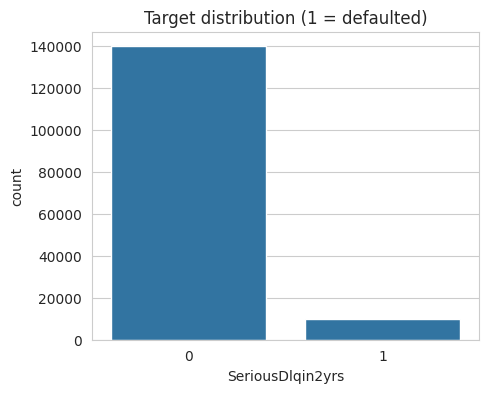

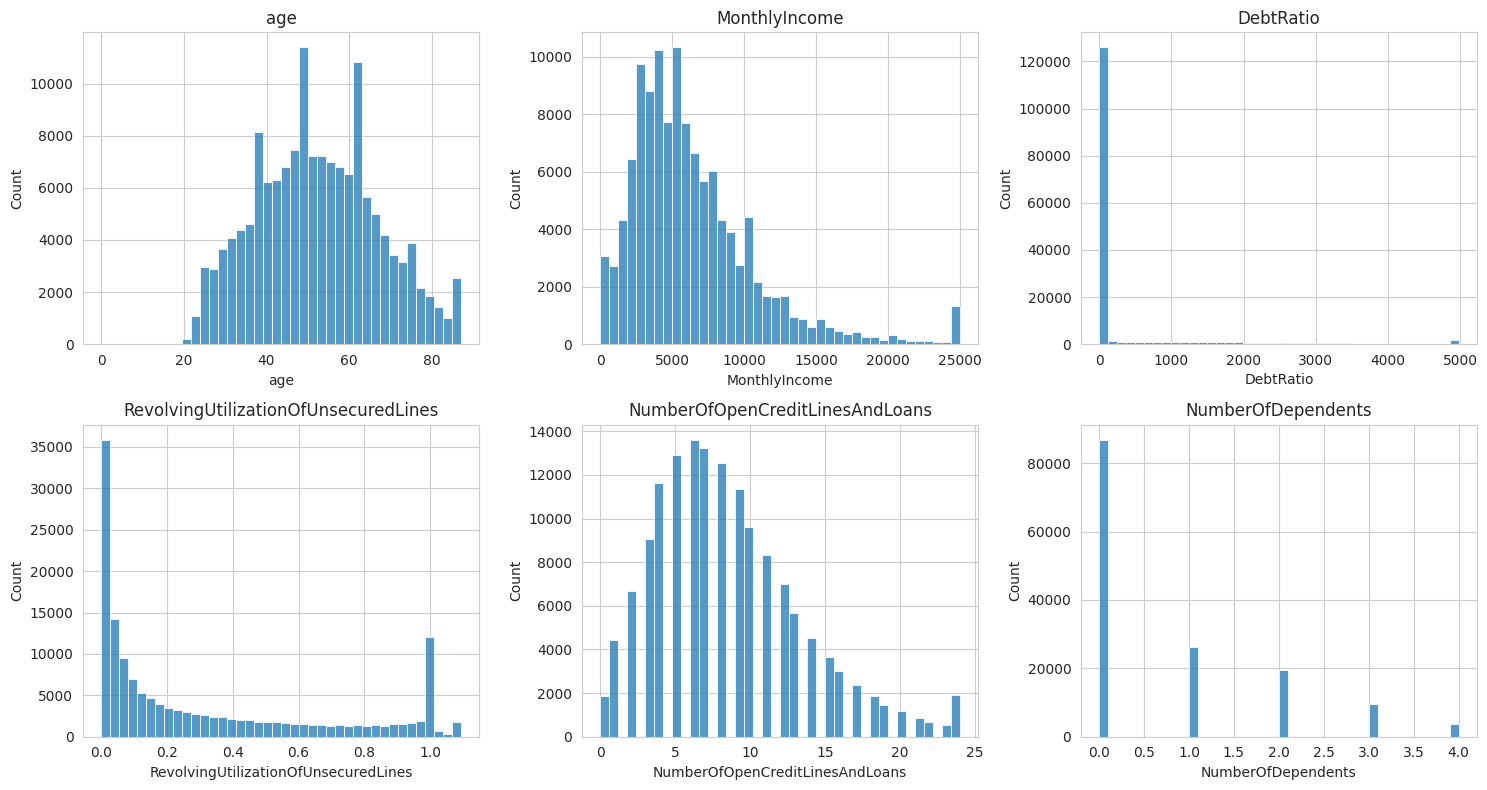

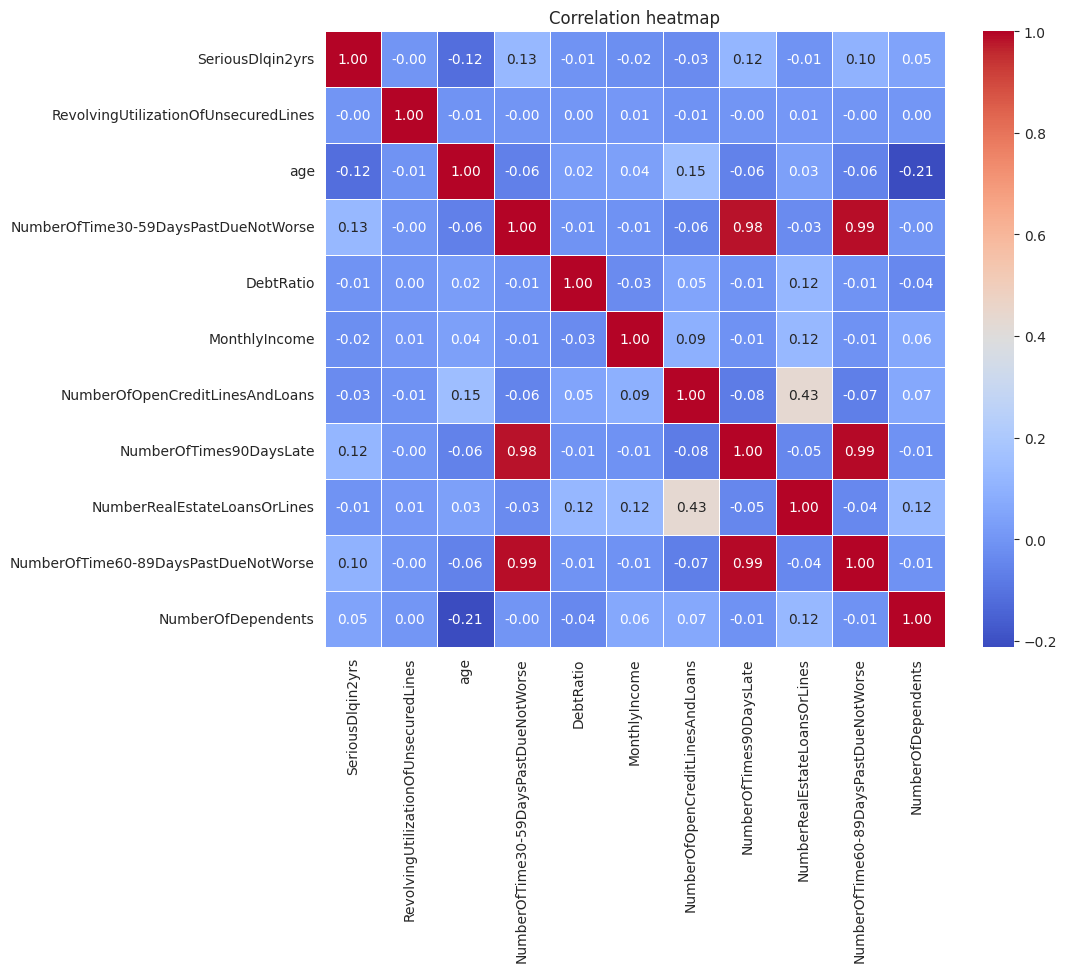

In [3]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
df.describe().T
# Target distribution (class imbalance)
counts = df[TARGET].value_counts()
print(counts, "\n")
print((counts / len(df) * 100).round(2).astype(str) + " %")

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=df)
plt.title("Target distribution (1 = defaulted)")
plt.show()
# Distributions of key features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["age", "MonthlyIncome", "DebtRatio",
                                  "RevolvingUtilizationOfUnsecuredLines",
                                  "NumberOfOpenCreditLinesAndLoans", "NumberOfDependents"]):
    sns.histplot(df[col].dropna().clip(upper=df[col].quantile(0.99)), bins=40, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

In [4]:
df = df[df["age"] >= 18].copy()

late_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]
for c in late_cols:
    df[c] = df[c].replace([96, 98], np.nan)

print("Rows after cleaning:", len(df))

Rows after cleaning: 149999


In [5]:
df["TotalPastDue"] = df[late_cols].sum(axis=1, skipna=False)
df["HasLatePayment"] = (df["TotalPastDue"] > 0).astype(int)
df["IncomePerDependent"] = df["MonthlyIncome"] / (df["NumberOfDependents"].fillna(0) + 1)
df["MonthlyDebtAmount"] = df["DebtRatio"] * df["MonthlyIncome"]
df["CreditLinesPerAge"] = df["NumberOfOpenCreditLinesAndLoans"] / df["age"]
df["HighUtilization"] = (df["RevolvingUtilizationOfUnsecuredLines"] > 0.8).astype(int)

# a NaN in TotalPastDue means an unknown value; HasLatePayment should not claim "no late payment" then
df.loc[df["TotalPastDue"].isna(), "HasLatePayment"] = np.nan

FLAG_COLS = ["HasLatePayment", "HighUtilization"]
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalPastDue,HasLatePayment,IncomePerDependent,MonthlyDebtAmount,CreditLinesPerAge,HighUtilization
0,1,0.766127,45,2.0,0.802982,9120.0,13,0.0,6,0.0,2.0,2.0,1.0,3040.0,7323.197016,0.288889,0
1,0,0.957151,40,0.0,0.121876,2600.0,4,0.0,0,0.0,1.0,0.0,0.0,1300.0,316.878123,0.100000,1
2,0,0.658180,38,1.0,0.085113,3042.0,2,1.0,0,0.0,0.0,2.0,1.0,3042.0,258.914887,0.052632,0
3,0,0.233810,30,0.0,0.036050,3300.0,5,0.0,0,0.0,0.0,0.0,0.0,3300.0,118.963951,0.166667,0
4,0,0.907239,49,1.0,0.024926,63588.0,7,0.0,1,0.0,0.0,1.0,1.0,63588.0,1584.975094,0.142857,1


In [6]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Median imputation (fitted on train only)
imputer = SimpleImputer(strategy="median").fit(X_train)
X_train = pd.DataFrame(imputer.transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

# Cap outliers at the train 99th percentile (continuous columns only)
cont_cols = [c for c in X.columns if c not in FLAG_COLS]
upper = X_train[cont_cols].quantile(0.99)
X_train[cont_cols] = X_train[cont_cols].clip(upper=upper, axis=1)
X_test[cont_cols] = X_test[cont_cols].clip(upper=upper, axis=1)

# Scaling (needed for Logistic Regression; trees don't need it)
scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Default rate  train: %.2f%%  test: %.2f%%" % (y_train.mean() * 100, y_test.mean() * 100))

Train: (119999, 16) | Test: (30000, 16)
Default rate  train: 6.68%  test: 6.68%


In [8]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                             class_weight="balanced", random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced",
                                             n_jobs=-1, random_state=RANDOM_STATE), False),
}

results, probs, preds, fitted = [], {}, {}, {}

for name, (model, use_scaled) in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if use_scaled else (X_train, X_test)
    model.fit(Xtr, y_train)
    y_prob = model.predict_proba(Xte)[:, 1]
    y_pred = model.predict(Xte)

    probs[name], preds[name], fitted[name] = y_prob, y_pred, model
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df
# Detailed report for each model
for name in models:
    print("=" * 60, f"\n{name}\n", "=" * 60)
    print(classification_report(y_test, preds[name], target_names=["No default", "Default"]))

Logistic Regression
              precision    recall  f1-score   support

  No default       0.98      0.80      0.88     27995
     Default       0.22      0.77      0.34      2005

    accuracy                           0.80     30000
   macro avg       0.60      0.78      0.61     30000
weighted avg       0.93      0.80      0.85     30000

Decision Tree
              precision    recall  f1-score   support

  No default       0.98      0.77      0.86     27995
     Default       0.20      0.79      0.32      2005

    accuracy                           0.77     30000
   macro avg       0.59      0.78      0.59     30000
weighted avg       0.93      0.77      0.83     30000

Random Forest
              precision    recall  f1-score   support

  No default       0.96      0.95      0.96     27995
     Default       0.40      0.48      0.44      2005

    accuracy                           0.92     30000
   macro avg       0.68      0.72      0.70     30000
weighted avg       0.92   

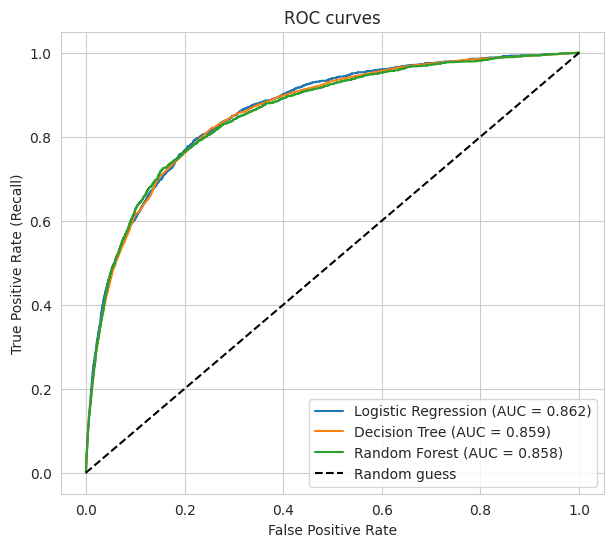

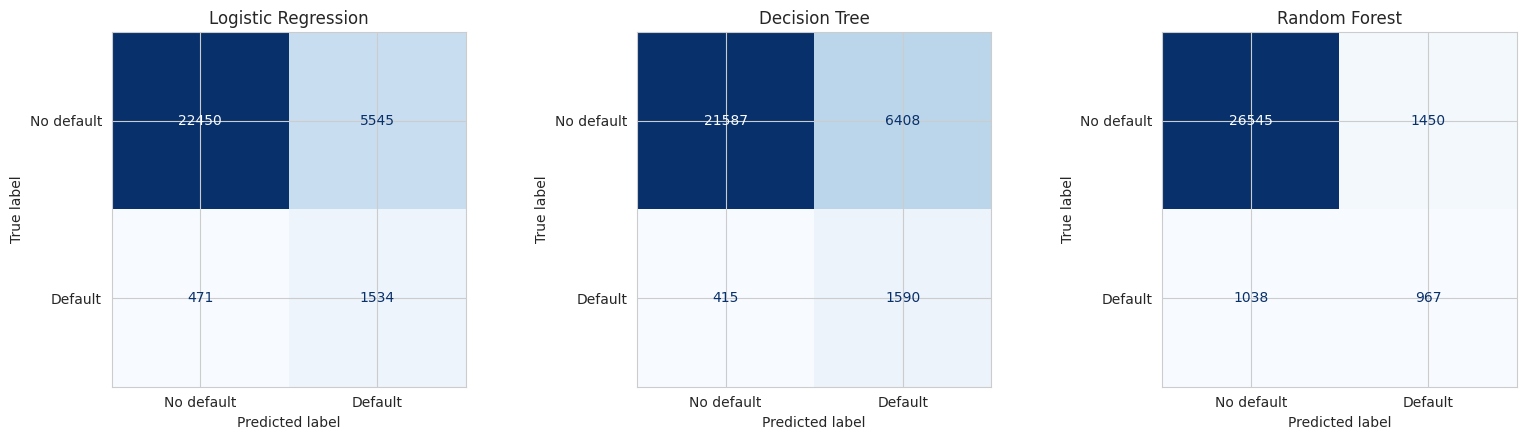

In [9]:
plt.figure(figsize=(7, 6))
for name, y_prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves")
plt.legend()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=["No default", "Default"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [10]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [6, 8, 10, 14, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": ["sqrt", "log2"],
}

search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=8, cv=3, scoring="roc_auc", n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV ROC-AUC: %.4f" % search.best_score_)

best_rf = search.best_estimator_
y_prob_best = best_rf.predict_proba(X_test)[:, 1]
y_pred_best = best_rf.predict(X_test)

print("\nTuned Random Forest on the test set")
print(classification_report(y_test, y_pred_best, target_names=["No default", "Default"]))
print("Test ROC-AUC: %.4f" % roc_auc_score(y_test, y_prob_best))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best params: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 'log2', 'max_depth': 8}
Best CV ROC-AUC: 0.8614

Tuned Random Forest on the test set
              precision    recall  f1-score   support

  No default       0.98      0.81      0.89     27995
     Default       0.23      0.76      0.35      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.79      0.62     30000
weighted avg       0.93      0.81      0.85     30000

Test ROC-AUC: 0.8678


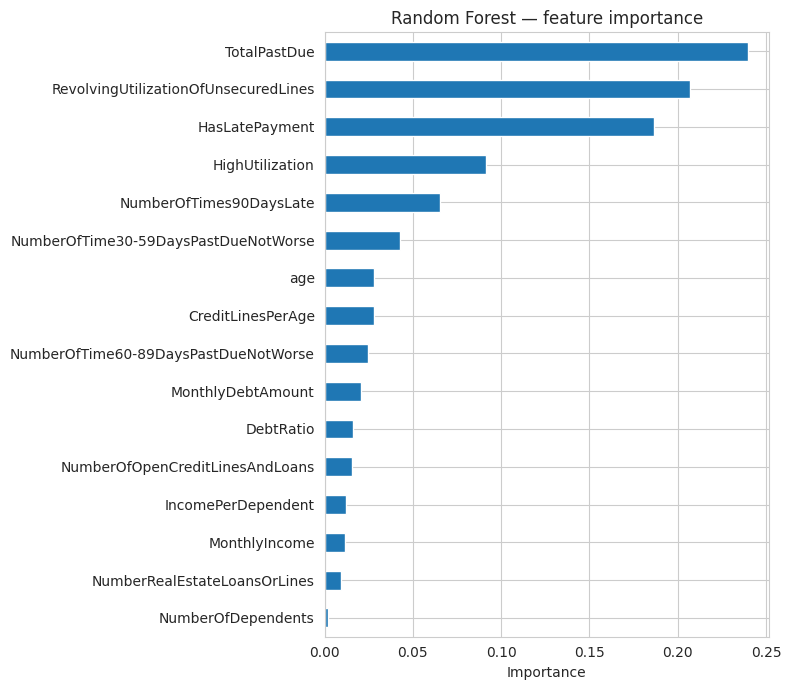

,0
TotalPastDue,0.239826
RevolvingUtilizationOfUnsecuredLines,0.206728
HasLatePayment,0.186866
HighUtilization,0.091645
NumberOfTimes90DaysLate,0.065310
NumberOfTime30-59DaysPastDueNotWorse,0.042826
age,0.027996
CreditLinesPerAge,0.027795


In [11]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 7))
importances.plot(kind="barh")
plt.title("Random Forest — feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

importances.sort_values(ascending=False).head(8)

In [12]:
rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    yp = (y_prob_best >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, yp, zero_division=0),
        "Recall": recall_score(y_test, yp),
        "F1-Score": f1_score(y_test, yp, zero_division=0),
    })
pd.DataFrame(rows).set_index("Threshold").round(4)

,Precision,Recall,F1-Score
Threshold,,,
0.2,0.1182,0.9392,0.2101
0.3,0.1467,0.8943,0.2521
0.4,0.1796,0.8414,0.2961
0.5,0.2282,0.7646,0.3515
0.6,0.2980,0.6529,0.4093
0.7,0.3511,0.5676,0.4339


In [13]:
try:
    from imblearn.over_sampling import SMOTE

    X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
    rf_smote = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                      n_jobs=-1, random_state=RANDOM_STATE).fit(X_res, y_res)
    p = rf_smote.predict_proba(X_test)[:, 1]
    yp = rf_smote.predict(X_test)

    compare = pd.DataFrame([
        {"Approach": "class_weight='balanced'", "Precision": precision_score(y_test, preds["Random Forest"]),
         "Recall": recall_score(y_test, preds["Random Forest"]), "F1-Score": f1_score(y_test, preds["Random Forest"]),
         "ROC-AUC": roc_auc_score(y_test, probs["Random Forest"])},
        {"Approach": "SMOTE", "Precision": precision_score(y_test, yp), "Recall": recall_score(y_test, yp),
         "F1-Score": f1_score(y_test, yp), "ROC-AUC": roc_auc_score(y_test, p)},
    ]).set_index("Approach").round(4)
    display(compare)
except ImportError:
    print("Install imbalanced-learn to run this cell:  pip install imbalanced-learn")

,Precision,Recall,F1-Score,ROC-AUC
Approach,,,,
class_weight='balanced',0.4001,0.4823,0.4374,0.8576
SMOTE,0.5030,0.2499,0.3339,0.8505


In [14]:
joblib.dump({"model": best_rf, "imputer": imputer, "features": list(X.columns), "cont_cols": cont_cols,
             "upper": upper}, "credit_scoring_model.joblib")

# Example: score one applicant (replace the numbers with your own)
applicant = pd.DataFrame([{
    "RevolvingUtilizationOfUnsecuredLines": 0.9, "age": 35,
    "NumberOfTime30-59DaysPastDueNotWorse": 2, "DebtRatio": 0.6, "MonthlyIncome": 4000,
    "NumberOfOpenCreditLinesAndLoans": 6, "NumberOfTimes90DaysLate": 1,
    "NumberRealEstateLoansOrLines": 1, "NumberOfTime60-89DaysPastDueNotWorse": 0, "NumberOfDependents": 2,
}])
applicant["TotalPastDue"] = applicant[late_cols].sum(axis=1)
applicant["HasLatePayment"] = (applicant["TotalPastDue"] > 0).astype(int)
applicant["IncomePerDependent"] = applicant["MonthlyIncome"] / (applicant["NumberOfDependents"] + 1)
applicant["MonthlyDebtAmount"] = applicant["DebtRatio"] * applicant["MonthlyIncome"]
applicant["CreditLinesPerAge"] = applicant["NumberOfOpenCreditLinesAndLoans"] / applicant["age"]
applicant["HighUtilization"] = (applicant["RevolvingUtilizationOfUnsecuredLines"] > 0.8).astype(int)
applicant = applicant[X.columns]
applicant[cont_cols] = applicant[cont_cols].clip(upper=upper, axis=1)

risk = best_rf.predict_proba(applicant)[0, 1]
print(f"Probability of default: {risk:.1%}  ->  {'HIGH RISK' if risk >= 0.5 else 'LOW RISK'}")

Probability of default: 93.1%  ->  HIGH RISK
